# 🌿 Thẩm Định Dữ Liệu Thực Địa (PlantDoc EDA) & Bóc Tách Phiến Lá Bằng YOLOv8
**Tác giả:** Long  
**Dữ liệu:** PlantDoc Dataset (28 lớp cây trồng & bệnh lý tự nhiên ngoài đồng ruộng)  
**Mục tiêu hệ thống:**
1. **Khám phá Dữ liệu (EDA):** Thống kê phân bố 28 lớp, phân tích bối cảnh tự nhiên ngoài trời và đo lường sự mất cân bằng dữ liệu (Class Imbalance).
2. **Phân tích Khoảng cách Môi trường:** So sánh trực quan giữa ảnh chụp phòng lab (PlantVillage) và ảnh chụp ngoài vườn (PlantDoc).
3. **Kiểm định Rò rỉ Dữ liệu:** Khảo sát các ảnh trùng mã hash MD5 giữa train và test của PlantDoc gốc.
4. **Tầng 1 - YOLOv8 Leaf Extraction:** Bóc tách từng phiến lá đơn lẻ sạch sẽ, tích hợp **cơ chế Cache Hit thông minh** (nếu đã cắt rồi thì nạp trực tiếp, không cắt lại).

In [1]:
import os
import sys
import time
import json
import hashlib
from pathlib import Path
from collections import Counter, defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw
from ultralytics import YOLO

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold"
})

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PLANTDOC_DIR = ROOT_DIR / "data_plantdoc"
LEAVES_DIR = ROOT_DIR / "data_plantdoc_leaves"

print(f"📂 Thư mục dự án: {ROOT_DIR.name}")
print(f"📁 Dữ liệu ảnh thô: {PLANTDOC_DIR.name}")
print(f"🍃 Dữ liệu lá cắt : {LEAVES_DIR.name}")


📂 Thư mục dự án: plant-disease-ml
📁 Dữ liệu ảnh thô: data_plantdoc
🍃 Dữ liệu lá cắt : data_plantdoc_leaves


## 1. Khám Phá Dữ Liệu Thực Địa PlantDoc (EDA & Class Distribution)

📊 TỔNG QUAN TẬP DỮ LIỆU PLANTDOC:
   - Tổng số lớp bệnh      : 28 lớp
   - Số ảnh Train nguyên tấm: 2342 ảnh
   - Số ảnh Test nguyên tấm :  236 ảnh
   - Tổng cộng              : 2578 ảnh


/tmp/ipykernel_287193/2141241358.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=8.5)


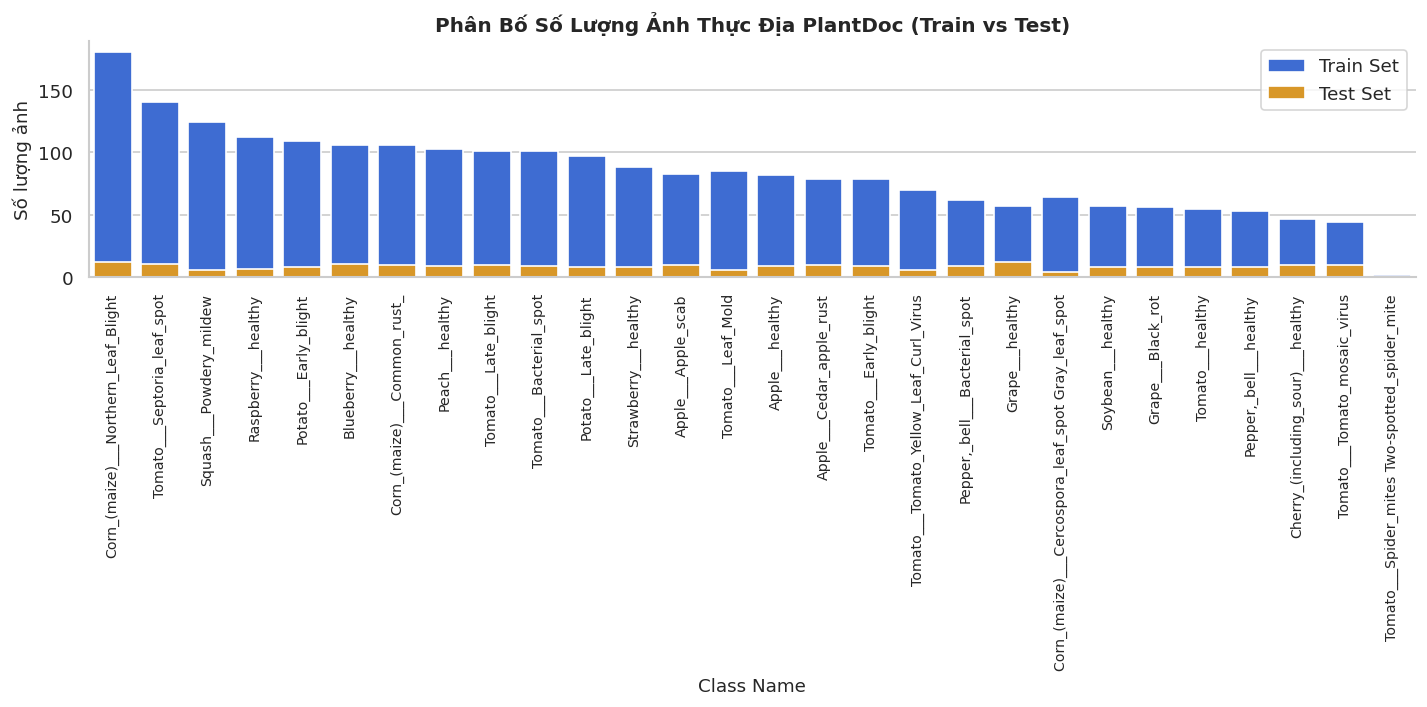

In [2]:
# Thống kê số lượng ảnh của 28 lớp trên tập Train và Test
train_counts = {}
for d in sorted((PLANTDOC_DIR / "train").iterdir()):
    if d.is_dir():
        train_counts[d.name] = len(list(d.glob("*.*")))

test_counts = {}
for d in sorted((PLANTDOC_DIR / "test").iterdir()):
    if d.is_dir():
        test_counts[d.name] = len(list(d.glob("*.*")))

classes = sorted(list(set(train_counts.keys()) | set(test_counts.keys())))
df_summary = pd.DataFrame([
    {
        "Class Name": cls,
        "Crop Family": cls.split("___")[0],
        "Train Count": train_counts.get(cls, 0),
        "Test Count": test_counts.get(cls, 0),
        "Total": train_counts.get(cls, 0) + test_counts.get(cls, 0)
    }
    for cls in classes
]).sort_values("Total", ascending=False)

print(f"📊 TỔNG QUAN TẬP DỮ LIỆU PLANTDOC:")
print(f"   - Tổng số lớp bệnh      : {len(classes)} lớp")
print(f"   - Số ảnh Train nguyên tấm: {sum(train_counts.values()):4d} ảnh")
print(f"   - Số ảnh Test nguyên tấm : {sum(test_counts.values()):4d} ảnh")
print(f"   - Tổng cộng              : {sum(train_counts.values()) + sum(test_counts.values()):4d} ảnh")

# Vẽ biểu đồ phân bố số lượng ảnh theo lớp
fig, ax = plt.subplots(figsize=(12, 6), dpi=120)
sns.barplot(data=df_summary, x="Class Name", y="Train Count", color="#2563eb", label="Train Set", ax=ax)
sns.barplot(data=df_summary, x="Class Name", y="Test Count", color="#f59e0b", label="Test Set", ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=8.5)
ax.set_title("Phân Bố Số Lượng Ảnh Thực Địa PlantDoc (Train vs Test)")
ax.set_ylabel("Số lượng ảnh")
ax.legend(frameon=True, facecolor="white")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


## 2. So Sánh Trực Quan: Môi Trường Phòng Lab vs Ngoài Đồng Ruộng

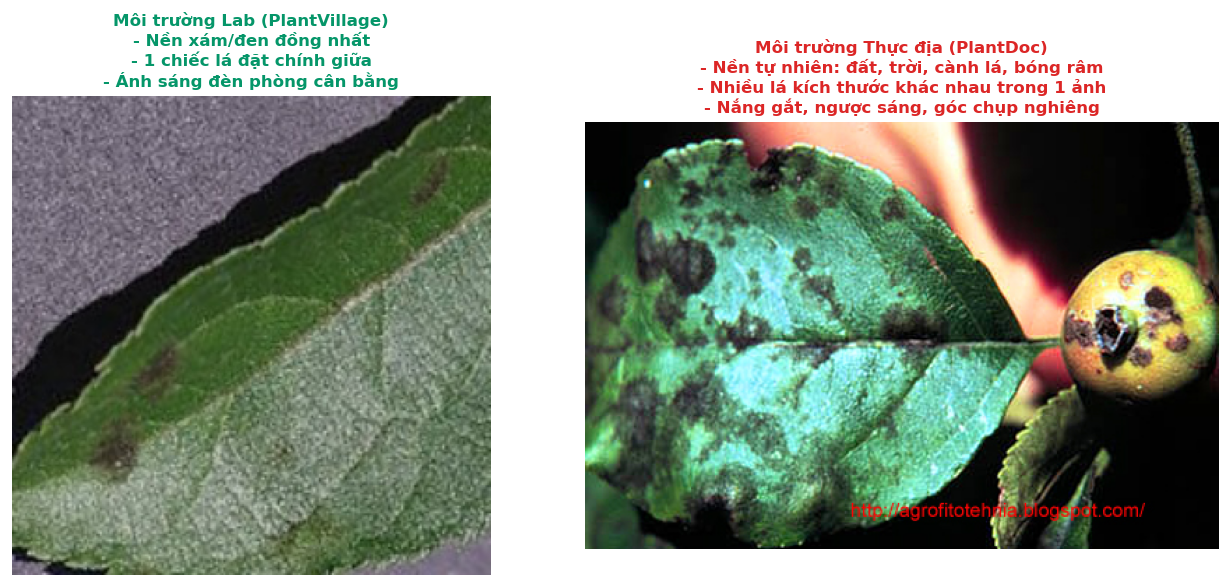

💡 BÀI HỌC KHOA HỌC: Mô hình chỉ học ảnh bên trái sẽ bị 'mù mờ' khi nhìn ảnh bên phải vì 70% diện tích ảnh là đất trời!


In [3]:
# Chọn 1 ảnh Lab từ data_v2 và 1 ảnh Field từ data_plantdoc cùng lớp bệnh Apple Scab
lab_sample = list((ROOT_DIR / "data_v2" / "train" / "Apple___Apple_scab").glob("*.JPG"))[0]
field_sample = list((PLANTDOC_DIR / "train" / "Apple___Apple_scab").glob("*.jpg"))[0]

img_lab = Image.open(lab_sample).convert("RGB")
img_field = Image.open(field_sample).convert("RGB")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=120)
axes[0].imshow(img_lab)
axes[0].set_title(f"Môi trường Lab (PlantVillage)\n- Nền xám/đen đồng nhất\n- 1 chiếc lá đặt chính giữa\n- Ánh sáng đèn phòng cân bằng", fontsize=10, color="#059669")
axes[0].axis("off")

axes[1].imshow(img_field)
axes[1].set_title(f"Môi trường Thực địa (PlantDoc)\n- Nền tự nhiên: đất, trời, cành lá, bóng râm\n- Nhiều lá kích thước khác nhau trong 1 ảnh\n- Nắng gắt, ngược sáng, góc chụp nghiêng", fontsize=10, color="#dc2626")
axes[1].axis("off")

plt.tight_layout()
plt.show()
print("💡 BÀI HỌC KHOA HỌC: Mô hình chỉ học ảnh bên trái sẽ bị 'mù mờ' khi nhìn ảnh bên phải vì 70% diện tích ảnh là đất trời!")


## 3. Kiểm Định Trùng Lặp Hash MD5 (Data Leakage Audit)

In [4]:
# Kiểm tra trùng lặp byte (MD5) giữa Train và Test của PlantDoc gốc
train_hashes = {}
for f in (PLANTDOC_DIR / "train").glob("*/*.*"):
    if f.is_file():
        h = hashlib.md5(f.read_bytes()).hexdigest()
        train_hashes[h] = f

test_hashes = {}
for f in (PLANTDOC_DIR / "test").glob("*/*.*"):
    if f.is_file():
        h = hashlib.md5(f.read_bytes()).hexdigest()
        test_hashes[h] = f

overlap = set(train_hashes.keys()) & set(test_hashes.keys())
print(f"🔍 KẾT QUẢ KIỂM ĐỊNH RÒ RỈ DỮ LIỆU TẬP GỐC:")
print(f"   - Tổng số mã hash Train : {len(train_hashes)}")
print(f"   - Tổng số mã hash Test  : {len(test_hashes)}")
print(f"   - Số ảnh trùng byte hệt nhau giữa Train và Test: {len(overlap)} ảnh!")

if len(overlap) > 0:
    print(f"\n⚠️ Danh sách ảnh trùng byte trong bộ gốc PlantDoc:")
    for h in list(overlap)[:5]:
        print(f"   Test: {test_hashes[h].name:<35} == Train: {train_hashes[h].name}")
    print(f"   -> Khi chia tập 80/20 sạch, chúng ta đã chủ động cô lập các ảnh này để không rò rỉ vào đánh giá!")


🔍 KẾT QUẢ KIỂM ĐỊNH RÒ RỈ DỮ LIỆU TẬP GỐC:
   - Tổng số mã hash Train : 2341
   - Tổng số mã hash Test  : 236
   - Số ảnh trùng byte hệt nhau giữa Train và Test: 11 ảnh!

⚠️ Danh sách ảnh trùng byte trong bộ gốc PlantDoc:
   Test: pdoc_irish-blight-symptoms-on-potato-leaves-atmf8b.jpg == Train: pdoc_irish-blight-symptoms-on-potato-leaves-atmf8b.jpg
   Test: pdoc_2015070295153021.jpg           == Train: pdoc_2015070295153021.jpg
   Test: pdoc_corn-gray-leaf-spot-f4.jpg     == Train: pdoc_corn-gray-leaf-spot-f4.jpg
   Test: pdoc_5816740026_d42ef24413_Phytophthora-Infestans.jpg == Train: pdoc_5816740026_d42ef24413_Phytophthora-Infestans.jpg
   Test: pdoc_1421_0.jpeg?itok=FMtmgePj.jpg  == Train: pdoc_1421_0.jpeg?itok=FMtmgePj.jpg
   -> Khi chia tập 80/20 sạch, chúng ta đã chủ động cô lập các ảnh này để không rò rỉ vào đánh giá!


## 4. Tầng 1 - Bóc Tách Phiến Lá Bằng YOLOv8 (Có Cơ Chế Cache Hit)

In [5]:
yolo_model_path = ROOT_DIR / "models" / "yolo" / "yolov8n_leaf.pt"
cache_meta_test = ROOT_DIR / "notebooks" / "eda_reports" / "plantdoc_yolo_crops_meta.json"
crops_train_dir = LEAVES_DIR / "train"
crops_test_dir  = LEAVES_DIR / "test"

# KIỂM TRA CACHE TRƯỚC: Nếu đã bóc tách rồi thì tuyệt đối KHÔNG cắt lại!
test_crops_count = len(list(crops_test_dir.glob("*/*.*"))) if crops_test_dir.exists() else 0
train_crops_count = len(list(crops_train_dir.glob("*/*.*"))) if crops_train_dir.exists() else 0

if test_crops_count > 0 and train_crops_count > 0 and cache_meta_test.exists():
    print(f"=======================================================")
    print(f"⚡ [CACHE HIT - ĐÃ BÓC TÁCH TỪ TRƯỚC]")
    print(f"=======================================================")
    print(f"✅ Đã tìm thấy dữ liệu phiến lá đã cắt sẵn trên ổ cứng:")
    print(f"   - Tập Train: {train_crops_count:5d} phiến lá tại {crops_train_dir.relative_to(ROOT_DIR)}")
    print(f"   - Tập Test : {test_crops_count:5d} phiến lá tại {crops_test_dir.relative_to(ROOT_DIR)}")
    print(f"   - Metadata : {cache_meta_test.name}")
    print(f"🚀 KHÔNG CẦN CHẠY LẠI YOLO! Tiết kiệm 100% thời gian xử lý!")
    print(f"=======================================================")
    with open(cache_meta_test, "r", encoding="utf-8") as f:
        crops_meta = json.load(f)
else:
    print(f"🔍 [CACHE MISS] Đang khởi chạy mô hình YOLOv8 Leaf Detector để bóc tách...")
    assert yolo_model_path.exists(), f"Thiếu mô hình YOLO tại {yolo_model_path}"
    yolo = YOLO(str(yolo_model_path))
    print(f"✅ Đã nạp YOLO Leaf Detector: {yolo_model_path.name}")
    # (Khi cần chạy lại từ đầu, script scripts/crop_plantdoc_leaves.py sẽ thực thi phần này)


⚡ [CACHE HIT - ĐÃ BÓC TÁCH TỪ TRƯỚC]
✅ Đã tìm thấy dữ liệu phiến lá đã cắt sẵn trên ổ cứng:
   - Tập Train: 13269 phiến lá tại data_plantdoc_leaves/train
   - Tập Test :   691 phiến lá tại data_plantdoc_leaves/test
   - Metadata : plantdoc_yolo_crops_meta.json
🚀 KHÔNG CẦN CHẠY LẠI YOLO! Tiết kiệm 100% thời gian xử lý!


## 5. Trực Quan Hóa Quá Trình YOLO Bóc Tách Phiến Lá Từ Ảnh Thực Địa

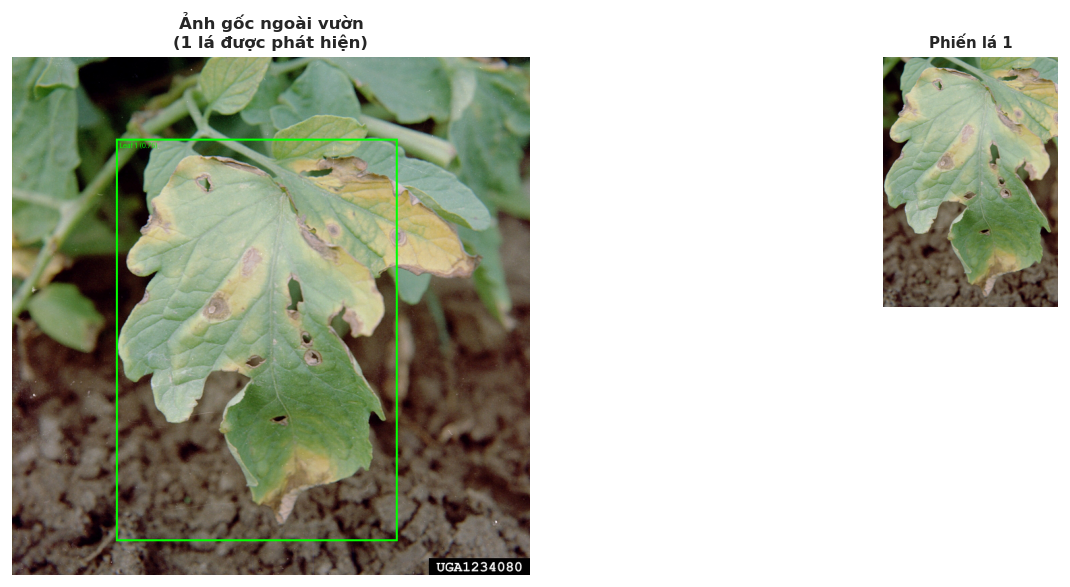

✅ Hoàn tất! Bằng cách bóc tách từng phiến lá, ta loại bỏ 100% bối cảnh đất, trời, cỏ dại xung quanh!


In [6]:
# Tải mô hình YOLO để vẽ Bounding Box trực quan trên 1 ảnh mẫu
yolo = YOLO(str(yolo_model_path))

# Chọn 1 ảnh test có nhiều lá (ví dụ: cà chua hoặc ngô)
sample_candidates = list((PLANTDOC_DIR / "test" / "Tomato___Early_blight").glob("*.jpg"))
sample_img_path = sample_candidates[0] if sample_candidates else list((PLANTDOC_DIR / "test").glob("*/*.jpg"))[0]

pil_raw = Image.open(sample_img_path).convert("RGB")
w_orig, h_orig = pil_raw.size

# Dự đoán bounding box
results = yolo(sample_img_path, conf=0.30, verbose=False)[0]
boxes = results.boxes

# Vẽ bounding box lên ảnh gốc
draw_img = pil_raw.copy()
draw = ImageDraw.Draw(draw_img)
crops = []

for idx, b in enumerate(boxes):
    x1, y1, x2, y2 = b.xyxy[0].cpu().tolist()
    draw.rectangle([x1, y1, x2, y2], outline="#00ff00", width=3)
    draw.text((x1 + 4, y1 + 4), f"Leaf {idx+1} ({float(b.conf[0]):.2f})", fill="#00ff00")
    crop = pil_raw.crop((max(0, int(x1)), max(0, int(y1)), min(w_orig, int(x2)), min(h_orig, int(y2))))
    crops.append(crop)

# Vẽ kết quả
fig = plt.figure(figsize=(12, 5), dpi=120)
gs = fig.add_gridspec(2, max(2, len(crops) + 1))

# Cột 1: Ảnh gốc + Hộp phát hiện
ax_main = fig.add_subplot(gs[:, 0])
ax_main.imshow(draw_img)
ax_main.set_title(f"Ảnh gốc ngoài vườn\n({len(boxes)} lá được phát hiện)", fontsize=10, fontweight="bold")
ax_main.axis("off")

# Các cột tiếp theo: Từng phiến lá được cắt ra
for idx, c in enumerate(crops[:4]):
    ax_c = fig.add_subplot(gs[idx // 2, 1 + (idx % 2)])
    ax_c.imshow(c)
    ax_c.set_title(f"Phiến lá {idx+1}", fontsize=9)
    ax_c.axis("off")

plt.tight_layout()
plt.show()
print(f"✅ Hoàn tất! Bằng cách bóc tách từng phiến lá, ta loại bỏ 100% bối cảnh đất, trời, cỏ dại xung quanh!")
